
========== FIRST 5 ROWS ==========
   Study_Hours  Attendance  Marks
0         3.62       51.57  53.64
1         7.66       81.82  88.46
2         6.12       65.72  76.35
3         5.19       75.43  67.66
4         2.09       95.38  65.96

========== DATASET INFORMATION ==========
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Study_Hours  100 non-null    float64
 1   Attendance   100 non-null    float64
 2   Marks        100 non-null    float64
dtypes: float64(3)
memory usage: 2.5 KB

========== SUMMARY STATISTICS ==========
       Study_Hours  Attendance       Marks
count    100.00000  100.000000  100.000000
mean       4.29180   74.891500   66.266300
std        2.08272   14.655751   13.423856
min        1.04000   50.350000   41.450000
25%        2.35000   62.097500   55.985000
50%        4.25000   75.280000   65.555000
75%        6.11250   88.307500  

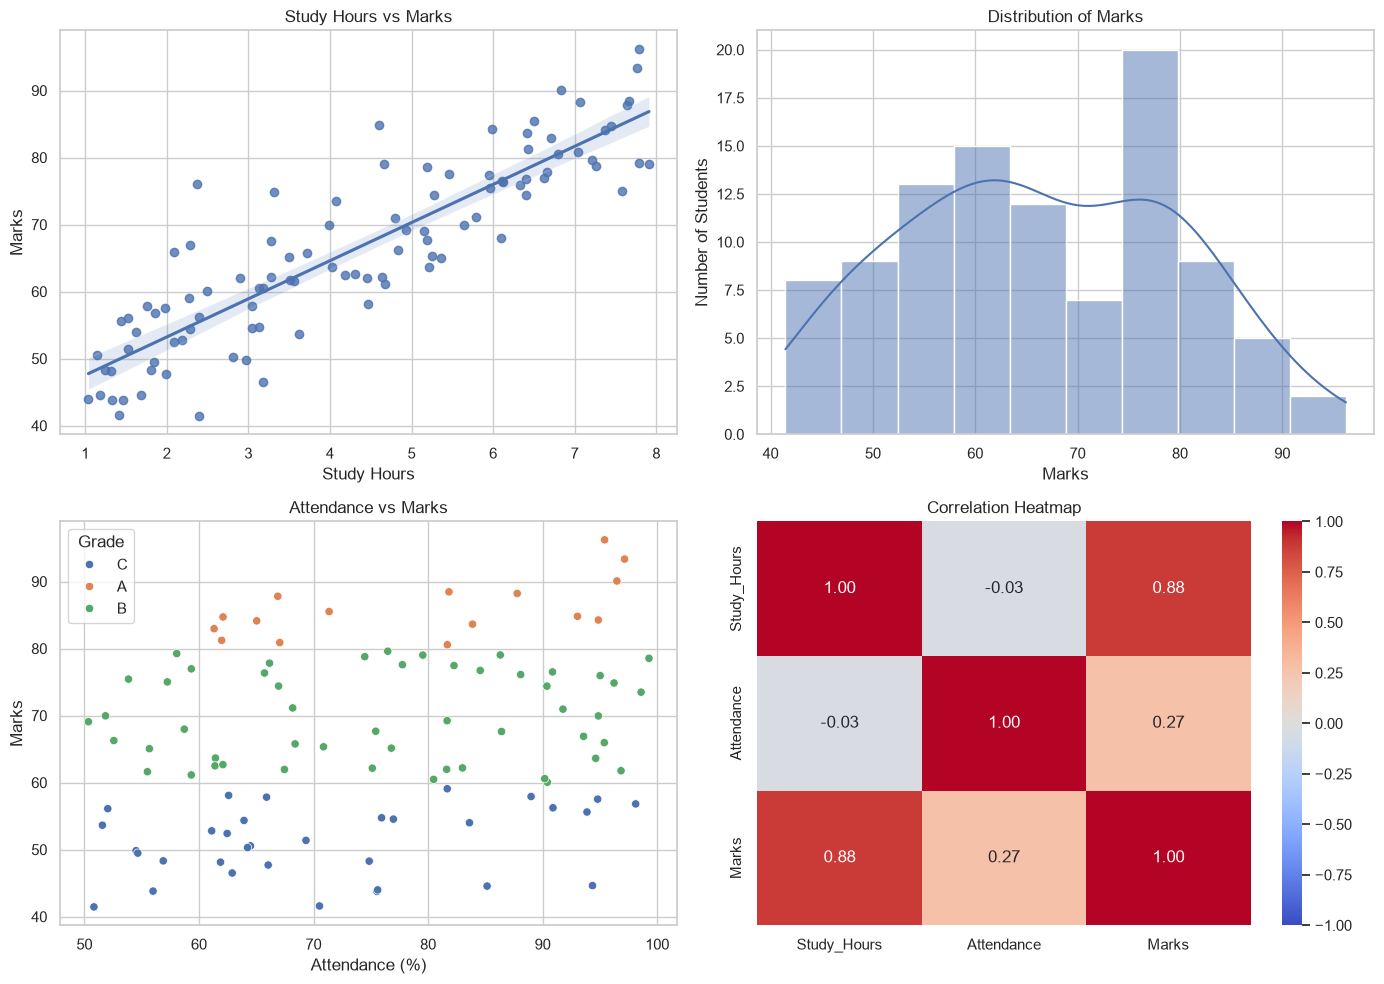

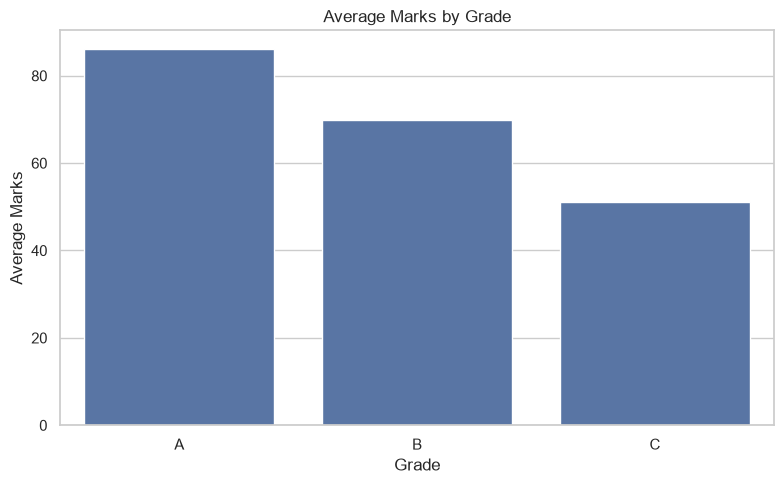

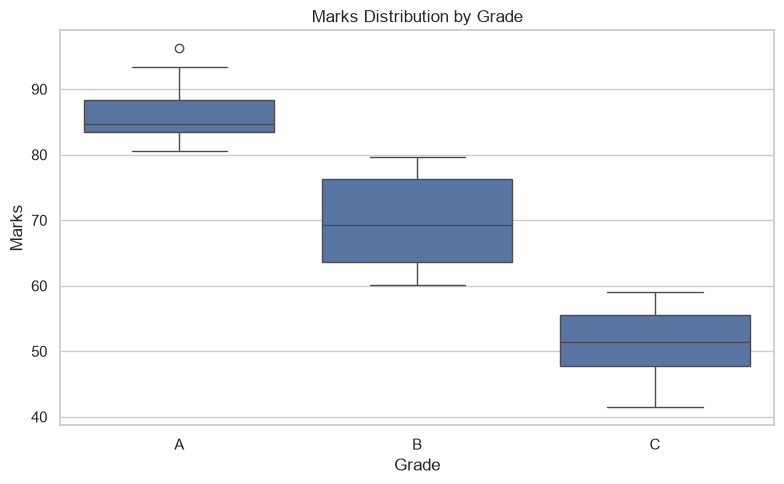


Analysis completed successfully!
Chart saved as student_performance_analysis.png
Dataset saved as student_performance.csv


In [1]:
# ==========================================
# STUDENT PERFORMANCE ANALYSIS
# NumPy + Pandas + Matplotlib + Seaborn
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# ==========================================
# 1. GENERATE DATA USING NUMPY
# ==========================================

np.random.seed(42)

n = 100

study_hours = np.random.uniform(1, 8, n)
attendance = np.random.uniform(50, 100, n)

marks = (
    25
    + study_hours * 6
    + attendance * 0.2
    + np.random.normal(0, 5, n)
)

marks = np.clip(marks, 0, 100)

# ==========================================
# 2. CREATE DATAFRAME USING PANDAS
# ==========================================

df = pd.DataFrame({
    "Study_Hours": study_hours,
    "Attendance": attendance,
    "Marks": marks
})

# Round numerical values
df["Study_Hours"] = df["Study_Hours"].round(2)
df["Attendance"] = df["Attendance"].round(2)
df["Marks"] = df["Marks"].round(2)

# ==========================================
# 3. DATA PREVIEW AND ANALYSIS
# ==========================================

print("\n========== FIRST 5 ROWS ==========")
print(df.head())

print("\n========== DATASET INFORMATION ==========")
df.info()

print("\n========== SUMMARY STATISTICS ==========")
print(df.describe())

print("\n========== AVERAGE MARKS ==========")
print(df["Marks"].mean())

print("\n========== MAXIMUM MARKS ==========")
print(df["Marks"].max())

print("\n========== MINIMUM MARKS ==========")
print(df["Marks"].min())

print("\n========== STUDENTS SCORING ABOVE 75 ==========")
print(df[df["Marks"] > 75])

# ==========================================
# 4. CREATE GRADE COLUMN USING PANDAS
# ==========================================

df["Grade"] = np.select(
    [
        df["Marks"] >= 80,
        df["Marks"] >= 60
    ],
    [
        "A",
        "B"
    ],
    default="C"
)

print("\n========== GRADE DISTRIBUTION ==========")
print(df["Grade"].value_counts())

print("\n========== AVERAGE MARKS BY GRADE ==========")
print(df.groupby("Grade")["Marks"].mean().round(2))

# ==========================================
# 5. CORRELATION ANALYSIS
# ==========================================

corr = df[
    ["Study_Hours", "Attendance", "Marks"]
].corr()

print("\n========== CORRELATION MATRIX ==========")
print(corr)

# ==========================================
# 6. VISUALIZATION USING MATPLOTLIB
#    AND SEABORN
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Chart 1: Study Hours vs Marks
sns.regplot(
    data=df,
    x="Study_Hours",
    y="Marks",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Study Hours vs Marks")
axes[0, 0].set_xlabel("Study Hours")
axes[0, 0].set_ylabel("Marks")

# Chart 2: Distribution of Marks
sns.histplot(
    data=df,
    x="Marks",
    bins=10,
    kde=True,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Distribution of Marks")
axes[0, 1].set_xlabel("Marks")
axes[0, 1].set_ylabel("Number of Students")

# Chart 3: Attendance vs Marks
sns.scatterplot(
    data=df,
    x="Attendance",
    y="Marks",
    hue="Grade",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Attendance vs Marks")
axes[1, 0].set_xlabel("Attendance (%)")
axes[1, 0].set_ylabel("Marks")

# Chart 4: Correlation Heatmap
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Correlation Heatmap")

plt.tight_layout()

# Save the visualization
plt.savefig(
    "student_performance_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 7. AVERAGE MARKS BY GRADE - BAR CHART
# ==========================================

grade_order = ["A", "B", "C"]

grade_average = (
    df.groupby("Grade")["Marks"]
    .mean()
    .reindex(grade_order)
    .dropna()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=grade_average.index,
    y=grade_average.values
)

plt.title("Average Marks by Grade")
plt.xlabel("Grade")
plt.ylabel("Average Marks")

plt.tight_layout()
plt.show()

# ==========================================
# 8. BOX PLOT FOR OUTLIER ANALYSIS
# ==========================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Grade",
    y="Marks",
    order=grade_order
)

plt.title("Marks Distribution by Grade")
plt.xlabel("Grade")
plt.ylabel("Marks")

plt.tight_layout()
plt.show()

# ==========================================
# 9. EXPORT DATA TO CSV
# ==========================================

df.to_csv("student_performance.csv", index=False)

print("\nAnalysis completed successfully!")
print("Chart saved as student_performance_analysis.png")
print("Dataset saved as student_performance.csv")